# AI vs Real Image Detection — Simplified AnomalyForensicNet (From Scratch)

Notebook ini melatih **`AnomalyForensicNet` (From Scratch)** yang telah **disederhanakan** khusus untuk dataset **`OwensLab/CommunityForensics` (CVPR 2025)** tanpa ketergantungan pada dataset *DEFACTO Inpainting* maupun *pixel-mask supervision*:

1. **Dataset Tunggal (`OwensLab/CommunityForensics`)**:
   - Menggunakan sampel seimbang **50% Real Image (`label=1`)** dan **50% AI-Generated (`label=0`)** dari `OwensLab/CommunityForensics` (`data/publicEval/HFCF_PublicEval_*.parquet`) dengan disk-caching lokal (`data/cf_cache`).
2. **Arsitektur `AnomalyForensicNet` yang Disederhanakan**:
   - **Tri-Stream Forensic Stem**: Menggabungkan `MultiScaleForensicFilterBankV4` (15-ch: Lap3, Lap5, DoG, Sobel, NPR), `ZeroMeanConv2d` (9-ch, $\sum W = 0$), `PhaseMagSpectralStem` (Log-Magnitude + Phase 2D-FFT), dan `RGB Stem`.
   - **4-Stage Mix-Kernel Backbone (`64 -> 128 -> 256 -> 384`)**: Konvolusi depthwise paralel `3x3 + 7x7` dengan `LayerNorm2dClean` dan `SqueezeExcitation`.
   - **Single-Task Classification (`TopKAnomalyPool2d` + Classifier Head)**: Menghapus *auxiliary mask head* (`14x14`) dan *inpainting inconsistency gate* sehingga pelatihan fokus penuh pada klasifikasi biner dengan `FocalLoss`.
3. **Suite Visualisasi Lengkap (Standar V4)**:
   - Grid sampel dataset `Real vs AI-Generated`, dekomposisi **7 Sinyal Forensik Multi-Domain**, kurva Loss/Accuracy/Macro-F1, **Confusion Matrix & Kurva ROC**, serta **Visualisasi Aktivasi Hirarkis Antar-Stage & Anomaly Saliency Overlay**.

In [ ]:
# ==============================================================================
# 1. SETUP & KONFIGURASI LINGKUNGAN
# ==============================================================================
import importlib.util, subprocess, sys

for pkg in ["pyarrow", "huggingface_hub"]:
    if importlib.util.find_spec(pkg) is None:
        print(f"Menginstal {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# Fix bug PyTorch + SymPy di Python 3.13 Colab (AttributeError: module 'sympy' has no attribute 'logic')
try:
    import sympy
    import sympy.logic.boolalg
    if not hasattr(sympy, "logic"):
        sympy.logic = importlib.import_module("sympy.logic")
except Exception:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "--force-reinstall", "sympy"])
    import sympy
    importlib.reload(sympy)
    import sympy.logic.boolalg

import os, io, gc, time, random, warnings
import numpy as np
import pandas as pd
from PIL import Image, ImageFile
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, roc_auc_score, roc_curve
)

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True

SEED = 42
seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Konfigurasi Eksperimen (Hanya OwensLab/CommunityForensics)
SAMPLES_PER_CLASS = 10000   # 6,000 Real (1) + 6,000 AI-Generated (0) = 12,000 sampel seimbang
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15
LR = 8e-4
WEIGHT_DECAY = 1e-2
PATIENCE = 5
MODEL_SAVE_PATH = "best_anomaly_forensicnet_cf.pth"

print(f"Perangkat komputasi : {device}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
print(f"Target Dataset      : OwensLab/CommunityForensics ({SAMPLES_PER_CLASS * 2:,} gambar seimbang)")
print(f"Checkpoint Output   : {MODEL_SAVE_PATH}")

Perangkat komputasi : cuda (NVIDIA A100-SXM4-80GB)
Target Dataset      : OwensLab/CommunityForensics (20,000 gambar seimbang)
Checkpoint Output   : best_anomaly_forensicnet_cf.pth


[*] Menyiapkan OwensLab/CommunityForensics (10,000 Real, 10,000 AI)...


Real Images (Label=1):  37%|###6      | 3692/10000 [00:00<?, ?it/s]

AI-Generated (Label=0):  49%|####9     | 4948/10000 [00:00<?, ?it/s]

[*] Mengunduh & mengekstrak shard: data/publicEval/HFCF_PublicEval_0.parquet...


[*] Mengunduh & mengekstrak shard: data/publicEval/HFCF_PublicEval_1.parquet...

Total Dataset Seimbang Dimuat: 20,000 sampel
class_name
Real            10000
AI-Generated    10000
Name: count, dtype: int64


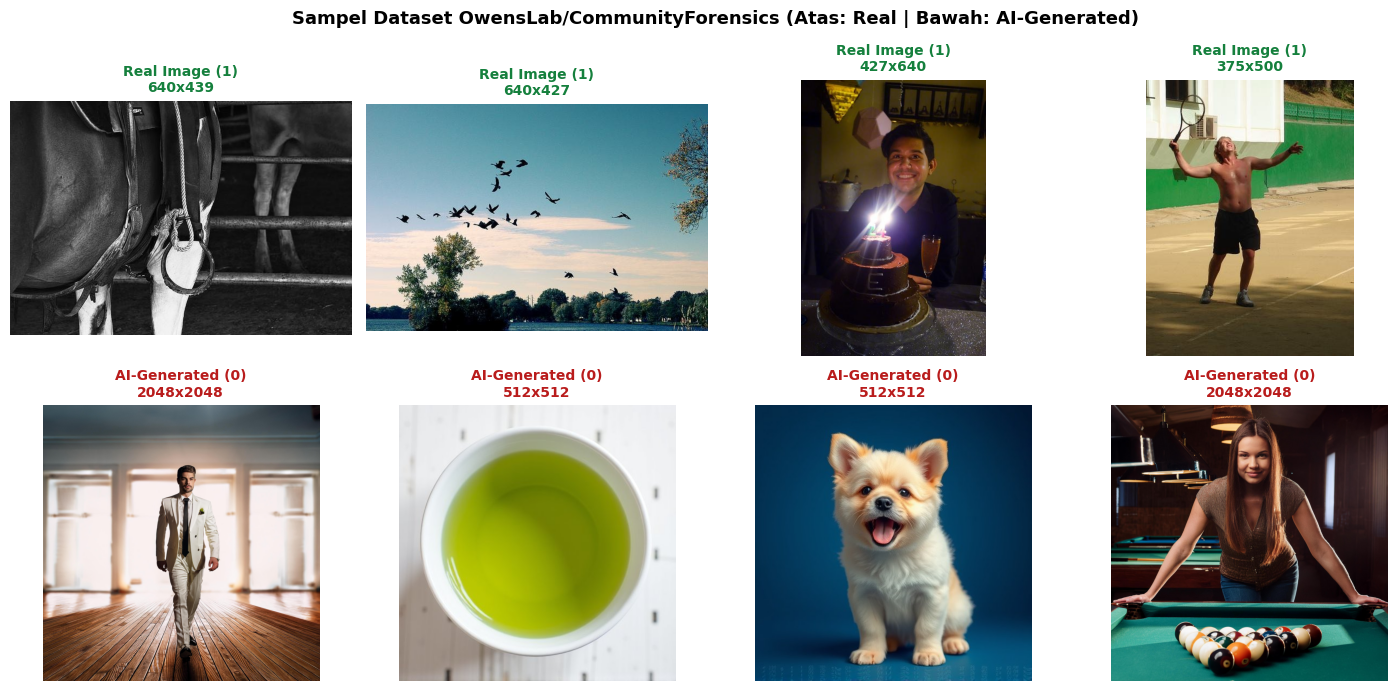

In [ ]:
# ==============================================================================
# 2. AKUISISI DATASET: OWENSLAB/COMMUNITYFORENSICS & VISUALISASI SAMPEL
# ==============================================================================
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download, login

VALID_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff")

def setup_hf_auth():
    token = os.environ.get("HF_TOKEN")
    if not token and os.path.exists(".env"):
        with open(".env", "r", encoding="utf-8") as f:
            for line in f:
                if line.strip().startswith("HF_TOKEN="):
                    token = line.strip().split("=", 1)[1].strip('"\'')
                    break
    if not token:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception:
            pass
    if token and token != "hf_isi_token_anda_disini":
        login(token=token, add_to_git_credential=False)
        print("Autentikasi Hugging Face berhasil.")
    return token

HF_TOKEN = setup_hf_auth()

def load_community_forensics(n_real: int = 6000, n_ai: int = 6000) -> pd.DataFrame:
    """
    Mengunduh dan mengekstrak citra dari OwensLab/CommunityForensics (data/publicEval/HFCF_PublicEval_*.parquet)
    dengan caching lokal di data/cf_cache agar cepat dan tidak mengunduh shard yang tidak diperlukan.
    """
    print(f"[*] Menyiapkan OwensLab/CommunityForensics ({n_real:,} Real, {n_ai:,} AI)...")
    CACHE_DIR = "data/cf_cache"
    os.makedirs(f"{CACHE_DIR}/ai", exist_ok=True)
    os.makedirs(f"{CACHE_DIR}/real", exist_ok=True)

    existing_ai = sorted([os.path.join(f"{CACHE_DIR}/ai", f) for f in os.listdir(f"{CACHE_DIR}/ai") if f.lower().endswith(VALID_EXTS)])
    existing_real = sorted([os.path.join(f"{CACHE_DIR}/real", f) for f in os.listdir(f"{CACHE_DIR}/real") if f.lower().endswith(VALID_EXTS)])
    count_ai, count_real = len(existing_ai), len(existing_real)

    if count_ai < n_ai or count_real < n_real:
        pbar_real = tqdm(total=n_real, initial=min(count_real, n_real), desc="Real Images (Label=1)")
        pbar_ai = tqdm(total=n_ai, initial=min(count_ai, n_ai), desc="AI-Generated (Label=0)")

        start_shard = min(5, min(count_real, count_ai) // 4100)
        shards = [f"data/publicEval/HFCF_PublicEval_{i}.parquet" for i in range(start_shard, 6)]

        for shard_path in shards:
            if count_ai >= n_ai and count_real >= n_real:
                break
            print(f"[*] Mengunduh & mengekstrak shard: {shard_path}...")
            local_pq = None
            try:
                local_pq = hf_hub_download(
                    repo_id="OwensLab/CommunityForensics",
                    filename=shard_path,
                    repo_type="dataset",
                    token=HF_TOKEN
                )
                pf = pq.ParquetFile(local_pq)
                rg_indices = list(range(pf.num_row_groups))
                random.shuffle(rg_indices)

                for rg_idx in rg_indices:
                    if count_ai >= n_ai and count_real >= n_real:
                        break
                    b_dict = pf.read_row_group(rg_idx).to_pydict()
                    labels = b_dict.get("label", [])
                    images = b_dict.get("image_data", b_dict.get("image", []))
                    paired = list(zip(labels, images))
                    random.shuffle(paired)

                    for lbl_val, img_data in paired:
                        if count_ai >= n_ai and count_real >= n_real:
                            break
                        # Di CommunityForensics: 0 = Real, 1 = AI/Fake
                        is_real = (int(lbl_val) == 0)
                        if (is_real and count_real >= n_real) or ((not is_real) and count_ai >= n_ai):
                            continue
                        try:
                            if isinstance(img_data, Image.Image):
                                img = img_data.convert("RGB")
                            elif isinstance(img_data, (bytes, bytearray)):
                                img = Image.open(io.BytesIO(img_data)).convert("RGB")
                            elif isinstance(img_data, dict) and img_data.get("bytes"):
                                img = Image.open(io.BytesIO(img_data["bytes"])).convert("RGB")
                            else:
                                continue
                        except Exception:
                            continue

                        if max(img.size) > 2048:
                            img.thumbnail((2048, 2048), Image.Resampling.BILINEAR)
                        rand_q = random.randint(80, 98)

                        if is_real:
                            save_p = f"{CACHE_DIR}/real/cf_real_{count_real:05d}.jpg"
                            if not os.path.exists(save_p):
                                img.save(save_p, "JPEG", quality=rand_q)
                            existing_real.append(save_p)
                            count_real += 1
                            pbar_real.update(1)
                        else:
                            save_p = f"{CACHE_DIR}/ai/cf_ai_{count_ai:05d}.jpg"
                            if not os.path.exists(save_p):
                                img.save(save_p, "JPEG", quality=rand_q)
                            existing_ai.append(save_p)
                            count_ai += 1
                            pbar_ai.update(1)
                del pf
            except Exception as err:
                print(f"[!] Gagal memproses {shard_path}: {err}")
            finally:
                gc.collect()
                if local_pq and os.path.exists(local_pq):
                    try:
                        os.remove(local_pq)
                    except OSError:
                        pass

        pbar_real.close()
        pbar_ai.close()

    records = []
    for p in existing_ai[:n_ai]:
        records.append({"image_path": p, "label": 0, "class_name": "AI-Generated"})
    for p in existing_real[:n_real]:
        records.append({"image_path": p, "label": 1, "class_name": "Real"})

    df = pd.DataFrame(records)
    n_bal = min((df["label"] == 0).sum(), (df["label"] == 1).sum())
    df_bal = pd.concat([
        df[df["label"] == 0].sample(n=n_bal, random_state=SEED),
        df[df["label"] == 1].sample(n=n_bal, random_state=SEED),
    ]).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    return df_bal

df_all = load_community_forensics(SAMPLES_PER_CLASS, SAMPLES_PER_CLASS)
print(f"\nTotal Dataset Seimbang Dimuat: {len(df_all):,} sampel")
print(df_all["class_name"].value_counts())

# --- Visualisasi Sampel Dataset (Real vs AI-Generated seperti V4) ---
def visualize_dataset_samples(df: pd.DataFrame, n_per_class: int = 4):
    real_rows = df[df["label"] == 1].sample(n=min(n_per_class, (df["label"] == 1).sum()), random_state=SEED)
    ai_rows = df[df["label"] == 0].sample(n=min(n_per_class, (df["label"] == 0).sum()), random_state=SEED)

    fig, axes = plt.subplots(2, n_per_class, figsize=(3.6 * n_per_class, 7.0))
    for i, (_, row) in enumerate(real_rows.iterrows()):
        img = Image.open(row["image_path"]).convert("RGB")
        axes[0, i].imshow(img)
        axes[0, i].set_title(f"Real Image (1)\n{img.size[0]}x{img.size[1]}", fontsize=10, fontweight="bold", color="#15803d")
        axes[0, i].axis("off")

    for i, (_, row) in enumerate(ai_rows.iterrows()):
        img = Image.open(row["image_path"]).convert("RGB")
        axes[1, i].imshow(img)
        axes[1, i].set_title(f"AI-Generated (0)\n{img.size[0]}x{img.size[1]}", fontsize=10, fontweight="bold", color="#b91c1c")
        axes[1, i].axis("off")

    plt.suptitle("Sampel Dataset OwensLab/CommunityForensics (Atas: Real | Bawah: AI-Generated)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

visualize_dataset_samples(df_all, n_per_class=4)

In [ ]:
# ==============================================================================
# 3. STRATIFIED SPLIT (80:10:10) & ANTI-SHORTCUT DATALOADER PIPELINE (STANDAR V4)
# ==============================================================================
class NativeResolutionCrop:
    """Crop 224x224 langsung dari resolusi asli agar artefak frekuensi tinggi/NPR tidak rusak oleh downsampling."""
    def __init__(self, size: int = 224, is_train: bool = True):
        self.size = size
        self.is_train = is_train

    def __call__(self, img: Image.Image) -> Image.Image:
        w, h = img.size
        if w < self.size or h < self.size:
            scale = max(self.size / w, self.size / h)
            img = img.resize((int(round(w * scale)), int(round(h * scale))), Image.Resampling.BILINEAR)
            w, h = img.size
        if self.is_train:
            left = random.randint(0, w - self.size)
            top = random.randint(0, h - self.size)
        else:
            left = (w - self.size) // 2
            top = (h - self.size) // 2
        return img.crop((left, top, left + self.size, top + self.size))

class RandomScaleJitter:
    """Mencegah shortcut resolusi tetap (misal 512x512 AI vs kamera asli) dengan acak skala sebelum crop."""
    def __init__(self, scale_range=(0.6, 1.4), p: float = 0.5):
        self.scale_range = scale_range
        self.p = p

    def __call__(self, img: Image.Image) -> Image.Image:
        if random.random() < self.p:
            w, h = img.size
            s = random.uniform(*self.scale_range)
            interp = Image.Resampling.BILINEAR if random.random() < 0.5 else Image.Resampling.BICUBIC
            return img.resize((max(IMAGE_SIZE, int(w * s)), max(IMAGE_SIZE, int(h * s))), interp)
        return img

class RandomJPEGCompression:
    """Mencegah shortcut learning antara PNG (AI) vs JPEG (Real) dengan kompresi acak."""
    def __init__(self, quality_range=(50, 95), p: float = 0.7):
        self.quality_range = quality_range
        self.p = p

    def __call__(self, img: Image.Image) -> Image.Image:
        if random.random() < self.p:
            buf = io.BytesIO()
            img.save(buf, format="JPEG", quality=random.randint(*self.quality_range))
            buf.seek(0)
            return Image.open(buf).convert("RGB")
        return img

train_transform = transforms.Compose([
    RandomScaleJitter(scale_range=(0.6, 1.4), p=0.5),
    RandomJPEGCompression(quality_range=(50, 95), p=0.7),
    NativeResolutionCrop(IMAGE_SIZE, is_train=True),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.8))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    NativeResolutionCrop(IMAGE_SIZE, is_train=False),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ForensicDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            img = Image.open(row["image_path"]).convert("RGB")
        except Exception:
            img = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (128, 128, 128))
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(int(row["label"]), dtype=torch.long)

train_df, temp_df = train_test_split(df_all, test_size=0.20, stratify=df_all["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

train_loader = DataLoader(ForensicDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(ForensicDataset(val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(ForensicDataset(test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Split Dataset -> Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

Split Dataset -> Train: 16,000 | Val: 2,000 | Test: 2,000


In [ ]:
# ==============================================================================
# 4. ARSITEKTUR SIMPLIFIED ANOMALYFORENSICNET (FROM SCRATCH)
# ==============================================================================
class MultiScaleForensicFilterBankV4(nn.Module):
    """Fixed 15-ch Forensic Filter Bank: Lap3, Lap5, DoG, Sobel Magnitude, dan NPR (CVPR 2024)."""
    def __init__(self):
        super().__init__()
        lap3 = torch.tensor([[0.0, -1.0, 0.0], [-1.0, 4.0, -1.0], [0.0, -1.0, 0.0]])
        lap5 = torch.tensor([
            [0.0,  0.0, -1.0,  0.0,  0.0],
            [0.0, -1.0, -2.0, -1.0,  0.0],
            [-1.0, -2.0, 16.0, -2.0, -1.0],
            [0.0, -1.0, -2.0, -1.0,  0.0],
            [0.0,  0.0, -1.0,  0.0,  0.0]
        ]) / 4.0
        dog5 = torch.tensor([
            [-1.0, -3.0, -4.0, -3.0, -1.0],
            [-3.0,  0.0,  6.0,  0.0, -3.0],
            [-4.0,  6.0, 20.0,  6.0, -4.0],
            [-3.0,  0.0,  6.0,  0.0, -3.0],
            [-1.0, -3.0, -4.0, -3.0, -1.0]
        ]) / 8.0
        sobel_x = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]])
        sobel_y = torch.tensor([[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]])

        self.register_buffer("k_lap3", lap3.view(1, 1, 3, 3).repeat(3, 1, 1, 1))
        self.register_buffer("k_lap5", lap5.view(1, 1, 5, 5).repeat(3, 1, 1, 1))
        self.register_buffer("k_dog5", dog5.view(1, 1, 5, 5).repeat(3, 1, 1, 1))
        self.register_buffer("k_sx", sobel_x.view(1, 1, 3, 3).repeat(3, 1, 1, 1))
        self.register_buffer("k_sy", sobel_y.view(1, 1, 3, 3).repeat(3, 1, 1, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        p1 = F.pad(x, (1, 1, 1, 1), mode="reflect")
        p2 = F.pad(x, (2, 2, 2, 2), mode="reflect")
        f_lap3 = F.conv2d(p1, self.k_lap3, groups=3)
        f_lap5 = F.conv2d(p2, self.k_lap5, groups=3)
        f_dog5 = F.conv2d(p2, self.k_dog5, groups=3)
        gx = F.conv2d(p1, self.k_sx, groups=3)
        gy = F.conv2d(p1, self.k_sy, groups=3)
        f_sobel = torch.sqrt(gx * gx + gy * gy + 1e-6)
        down = F.avg_pool2d(x, kernel_size=2, stride=2)
        up = F.interpolate(down, size=x.shape[-2:], mode="nearest")
        f_npr = (x - up) * 4.0
        return torch.clamp(torch.cat([f_lap3, f_lap5, f_dog5, f_sobel, f_npr], dim=1), -5.0, 5.0)


class ZeroMeanConv2d(nn.Module):
    """Learnable Forensic Filter dengan proyeksi zero-mean (sum(W) = 0) untuk menekan konten RGB."""
    def __init__(self, in_channels: int = 3, out_channels: int = 9, kernel_size: int = 5):
        super().__init__()
        self.padding = kernel_size // 2
        self.weight = nn.Parameter(torch.randn(out_channels, in_channels, kernel_size, kernel_size) * 0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        w = self.weight - self.weight.mean(dim=(2, 3), keepdim=True)
        w = w / (w.std(dim=(2, 3), keepdim=True) + 1e-5)
        return F.conv2d(F.pad(x, (self.padding,) * 4, mode="reflect"), w)


class LayerNorm2dClean(nn.Module):
    def __init__(self, num_channels: int, eps: float = 1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(num_channels))
        self.bias = nn.Parameter(torch.zeros(num_channels))
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        u = x.mean(1, keepdim=True)
        s = (x - u).pow(2).mean(1, keepdim=True)
        x = (x - u) / torch.sqrt(s + self.eps)
        return self.weight[:, None, None] * x + self.bias[:, None, None]


class PhaseMagSpectralStem(nn.Module):
    """Mengekstrak Log-Magnitude DAN Phase Spectrum dari 2D-FFT (6 kanal -> out_c)."""
    def __init__(self, in_c: int = 3, out_c: int = 32):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Conv2d(in_c * 2, out_c, kernel_size=3, stride=2, padding=1, bias=False),
            LayerNorm2dClean(out_c),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        orig_dtype = x.dtype
        fft = torch.fft.fft2(x.float(), norm="ortho")
        fft_shifted = torch.fft.fftshift(fft, dim=(-2, -1))
        mag = torch.log1p(torch.abs(fft_shifted))
        mag = mag / (mag.amax(dim=(-2, -1), keepdim=True) + 1e-6)
        phase = torch.angle(fft_shifted) / 3.14159265
        spec = torch.cat([mag, phase], dim=1).to(orig_dtype)
        return self.proj(spec)


class SqueezeExcitation(nn.Module):
    def __init__(self, channels: int, reduction: int = 4):
        super().__init__()
        mid = max(8, channels // reduction)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, mid, 1),
            nn.GELU(),
            nn.Conv2d(mid, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.fc(x)


class MixKernelForensicBlock(nn.Module):
    """Konvolusi Depthwise Paralel 3x3 (lokal) + 7x7 (konteks) dengan Inverted Bottleneck & SE."""
    def __init__(self, in_c: int, out_c: int, stride: int = 1):
        super().__init__()
        self.dw3 = nn.Conv2d(in_c, in_c, 3, stride=stride, padding=1, groups=in_c, bias=False)
        self.dw7 = nn.Conv2d(in_c, in_c, 7, stride=stride, padding=3, groups=in_c, bias=False)
        self.norm = LayerNorm2dClean(in_c)
        self.pw1 = nn.Conv2d(in_c, out_c * 2, 1, bias=False)
        self.act = nn.GELU()
        self.pw2 = nn.Conv2d(out_c * 2, out_c, 1, bias=False)
        self.se = SqueezeExcitation(out_c)
        self.skip = (
            nn.Sequential(nn.Conv2d(in_c, out_c, 1, stride=stride, bias=False), LayerNorm2dClean(out_c))
            if (stride != 1 or in_c != out_c) else nn.Identity()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        feat = self.norm(self.dw3(x) + self.dw7(x))
        feat = self.se(self.pw2(self.act(self.pw1(feat))))
        return feat + self.skip(x)


class TopKAnomalyPool2d(nn.Module):
    """Menggabungkan Mean + Std + Top-15% Spatial Activation Pooling."""
    def __init__(self, topk_ratio: float = 0.15):
        super().__init__()
        self.topk_ratio = topk_ratio

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, h, w = x.shape
        n = h * w
        k = max(1, int(round(n * self.topk_ratio)))
        flat = x.view(b, c, n)
        mean = flat.mean(dim=-1)
        std = torch.sqrt(flat.var(dim=-1, unbiased=False) + 1e-6)
        topk_mean = torch.topk(flat, k=k, dim=-1).values.mean(dim=-1)
        return torch.cat([mean, std, topk_mean], dim=1)


class AnomalyForensicNet(nn.Module):
    """
    Simplified AnomalyForensicNet (From-Scratch) untuk CommunityForensics (AI vs Real):
    - Tanpa auxiliary mask head & tanpa inpainting inconsistency gate yang tidak diperlukan.
    - Dilengkapi `forward_features(x)` untuk visualisasi aktivasi tiap stage seperti pada V4.
    """
    def __init__(self, num_classes: int = 2, dropout_p: float = 0.3):
        super().__init__()
        self.fixed_bank = MultiScaleForensicFilterBankV4()
        self.zeromean_conv = ZeroMeanConv2d(3, 9, kernel_size=5)
        self.forensic_stem = nn.Sequential(
            nn.Conv2d(24, 32, kernel_size=3, stride=2, padding=1, bias=False),
            LayerNorm2dClean(32),
            nn.GELU()
        )
        self.spectral_stem = PhaseMagSpectralStem(in_c=3, out_c=32)
        self.rgb_stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False),
            LayerNorm2dClean(32),
            nn.GELU()
        )
        self.fusion = nn.Sequential(
            nn.Conv2d(96, 64, kernel_size=1, bias=False),
            LayerNorm2dClean(64),
            nn.GELU()
        )

        self.stage1 = nn.Sequential(MixKernelForensicBlock(64, 64), MixKernelForensicBlock(64, 64))
        self.stage2 = nn.Sequential(MixKernelForensicBlock(64, 128, stride=2), MixKernelForensicBlock(128, 128))
        self.stage3 = nn.Sequential(MixKernelForensicBlock(128, 256, stride=2), MixKernelForensicBlock(256, 256))
        self.stage4 = nn.Sequential(MixKernelForensicBlock(256, 384, stride=2), MixKernelForensicBlock(384, 384))

        self.pool = TopKAnomalyPool2d(topk_ratio=0.15)
        self.head = nn.Sequential(
            nn.Dropout(p=dropout_p),
            nn.Linear(384 * 3, 192),
            nn.LayerNorm(192),
            nn.GELU(),
            nn.Dropout(p=0.15),
            nn.Linear(192, num_classes)
        )

    def forward_features(self, x: torch.Tensor):
        res_24 = torch.cat([self.fixed_bank(x), self.zeromean_conv(x)], dim=1)
        f_for = self.forensic_stem(res_24)
        f_spec = self.spectral_stem(x)
        f_rgb = self.rgb_stem(x)

        s0 = self.fusion(torch.cat([f_for, f_spec, f_rgb], dim=1))
        s1 = self.stage1(s0)
        s2 = self.stage2(s1)
        s3 = self.stage3(s2)
        s4 = self.stage4(s3)
        return s0, s1, s2, s3, s4

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        _, _, _, _, s4 = self.forward_features(x)
        return self.head(self.pool(s4))

model = AnomalyForensicNet(num_classes=2, dropout_p=0.3).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

with torch.no_grad():
    dummy_in = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    s0, s1, s2, s3, s4 = model.forward_features(dummy_in)
    dummy_out = model(dummy_in)

print(f"Arsitektur          : Simplified AnomalyForensicNet (From Scratch)")
print(f"Trainable Params    : {total_params:,} ({total_params / 1e6:.2f} Juta Parameter)")
print(f"Dimensi Tiap Stage  : Stem={tuple(s0.shape)} -> S1={tuple(s1.shape)} -> S2={tuple(s2.shape)} -> S3={tuple(s3.shape)} -> S4={tuple(s4.shape)}")
print(f"Output Logits Shape : {tuple(dummy_out.shape)}")

Arsitektur          : Simplified AnomalyForensicNet (From Scratch)
Trainable Params    : 2,383,333 (2.38 Juta Parameter)
Dimensi Tiap Stage  : Stem=(2, 64, 112, 112) -> S1=(2, 64, 112, 112) -> S2=(2, 128, 56, 56) -> S3=(2, 256, 28, 28) -> S4=(2, 384, 14, 14)
Output Logits Shape : (2, 2)


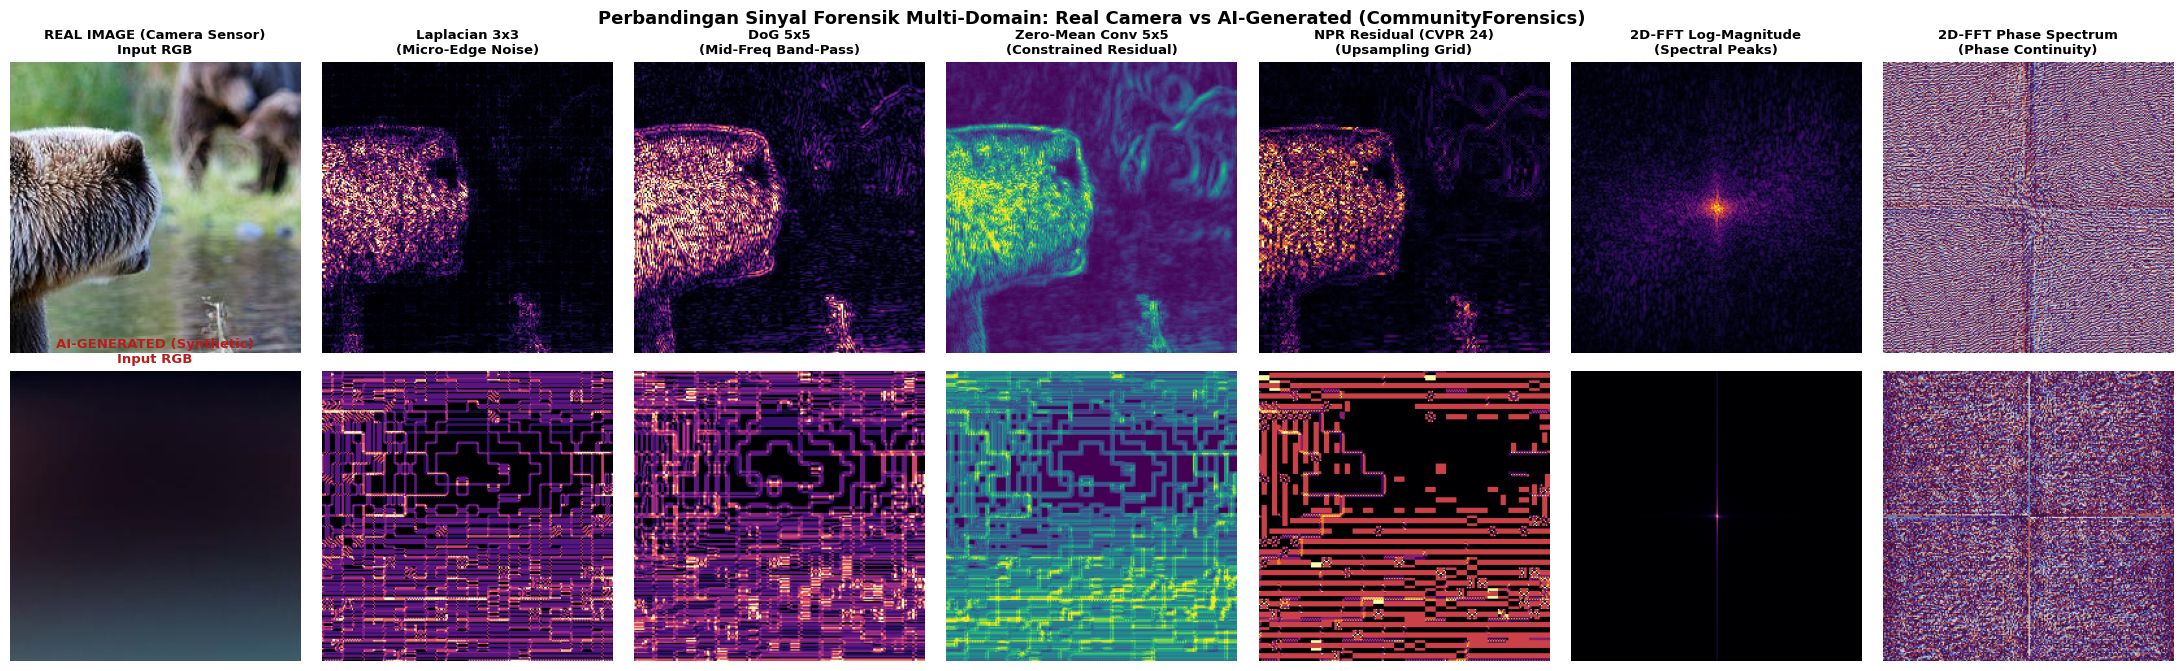

In [ ]:
# ==============================================================================
# 5. VISUALISASI EKSTRAKSI SINYAL FORENSIK MULTI-DOMAIN (SEPERTI V4)
# ==============================================================================
def denorm_img(t: torch.Tensor) -> np.ndarray:
    mean = torch.tensor([0.485, 0.456, 0.406], device=t.device).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=t.device).view(3, 1, 1)
    return torch.clamp(t * std + mean, 0, 1).permute(1, 2, 0).cpu().numpy()

def norm_map(t: torch.Tensor) -> np.ndarray:
    arr = t.abs().mean(dim=0).cpu().numpy()
    p99 = np.percentile(arr, 99) + 1e-6
    return np.clip(arr / p99, 0, 1)

def visualize_forensic_signals(df: pd.DataFrame):
    real_row = df[df["label"] == 1].iloc[0]
    ai_row = df[df["label"] == 0].iloc[0]

    samples = [("REAL IMAGE (Camera Sensor)", real_row), ("AI-GENERATED (Synthetic)", ai_row)]
    fig, axes = plt.subplots(2, 7, figsize=(22, 6.8))

    model.eval()
    with torch.no_grad():
        for r_idx, (title_prefix, row) in enumerate(samples):
            pil_img = Image.open(row["image_path"]).convert("RGB")
            x = eval_transform(pil_img).unsqueeze(0).to(device)

            fb = model.fixed_bank(x)[0]          # 15-ch: Lap3(0:3), Lap5(3:6), DoG5(6:9), Sobel(9:12), NPR(12:15)
            zm = model.zeromean_conv(x)[0]       # 9-ch Zero-Mean Conv
            fft = torch.fft.fftshift(torch.fft.fft2(x.float(), norm="ortho"), dim=(-2, -1))[0]
            fft_mag = torch.log1p(torch.abs(fft)).mean(dim=0).cpu().numpy()
            fft_mag = (fft_mag - fft_mag.min()) / (fft_mag.max() - fft_mag.min() + 1e-6)
            fft_phase = (torch.angle(fft).mean(dim=0).cpu().numpy() + np.pi) / (2 * np.pi)

            panels = [
                (denorm_img(x[0]), f"{title_prefix}\nInput RGB", None),
                (norm_map(fb[0:3]), "Laplacian 3x3\n(Micro-Edge Noise)", "magma"),
                (norm_map(fb[6:9]), "DoG 5x5\n(Mid-Freq Band-Pass)", "magma"),
                (norm_map(zm), "Zero-Mean Conv 5x5\n(Constrained Residual)", "viridis"),
                (norm_map(fb[12:15]), "NPR Residual (CVPR 24)\n(Upsampling Grid)", "inferno"),
                (fft_mag, "2D-FFT Log-Magnitude\n(Spectral Peaks)", "inferno"),
                (fft_phase, "2D-FFT Phase Spectrum\n(Phase Continuity)", "twilight"),
            ]

            for c_idx, (img_arr, col_title, cmap) in enumerate(panels):
                ax = axes[r_idx, c_idx]
                if cmap is None:
                    ax.imshow(img_arr)
                else:
                    ax.imshow(img_arr, cmap=cmap)
                if r_idx == 0:
                    ax.set_title(col_title, fontsize=9.5, fontweight="bold")
                elif c_idx == 0:
                    ax.set_title(col_title, fontsize=9.5, fontweight="bold", color="#b91c1c")
                ax.axis("off")

    plt.suptitle("Perbandingan Sinyal Forensik Multi-Domain: Real Camera vs AI-Generated (CommunityForensics)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

visualize_forensic_signals(test_df)

Memulai pelatihan Simplified AnomalyForensicNet pada OwensLab/CommunityForensics...


Epoch 01/15 [Train]:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 01/15 (267.8s) | Train Loss: 0.1521 Acc: 69.94% | Val Loss: 0.1240 Acc: 77.50% F1: 0.7737 ★ [BEST SAVED]


Epoch 02/15 [Train]:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 02/15 (246.9s) | Train Loss: 0.1260 Acc: 77.07% | Val Loss: 0.1109 Acc: 80.10% F1: 0.8001 ★ [BEST SAVED]


Epoch 03/15 [Train]:   0%|          | 0/500 [00:00<?, ?it/s]

... (29 outputs left out)

Epoch 14/15 (242.1s) | Train Loss: 0.0719 Acc: 89.20% | Val Loss: 0.0549 Acc: 92.50% F1: 0.9250 ★ [BEST SAVED]


Epoch 15/15 [Train]:   0%|          | 0/500 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78f00573ede0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78f00573ede0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 15/15 (248.3s) | Train Loss: 0.0709 Acc: 89.20% | Val Loss: 0.0535 Acc: 92.55% F1: 0.9255 ★ [BEST SAVED]


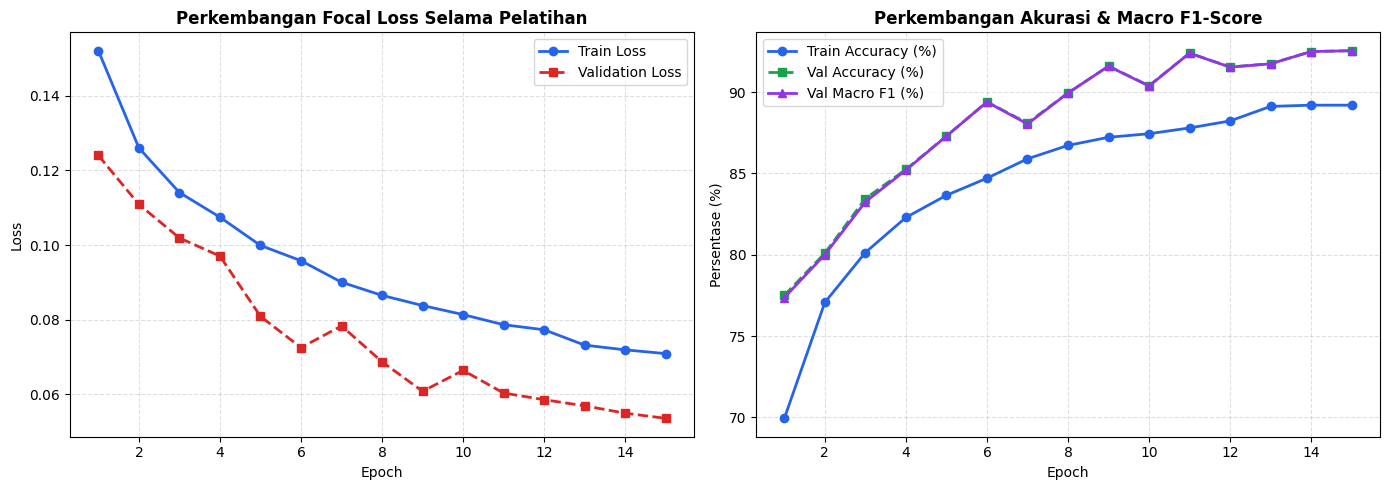

In [ ]:
# ==============================================================================
# 6. PELATIHAN MODEL (SINGLE-TASK FOCAL LOSS) & VISUALISASI KURVA TRAINING
# ==============================================================================
class FocalLoss(nn.Module):
    def __init__(self, gamma: float = 2.0, label_smoothing: float = 0.05):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce = F.cross_entropy(logits, targets, reduction="none", label_smoothing=self.label_smoothing)
        pt = torch.exp(-ce)
        return (((1.0 - pt) ** self.gamma) * ce).mean()

criterion = FocalLoss(gamma=2.0, label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
best_val_f1 = 0.0
patience_counter = 0

print("Memulai pelatihan Simplified AnomalyForensicNet pada OwensLab/CommunityForensics...")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    tr_loss, tr_preds, tr_targets = 0.0, [], []

    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS:02d} [Train]", leave=False):
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            logits = model(imgs)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        tr_loss += loss.item() * imgs.size(0)
        tr_preds.extend(logits.argmax(dim=1).cpu().numpy())
        tr_targets.extend(labels.cpu().numpy())

    scheduler.step()

    model.eval()
    vl_loss, vl_preds, vl_targets = 0.0, [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                logits = model(imgs)
                loss = criterion(logits, labels)
            vl_loss += loss.item() * imgs.size(0)
            vl_preds.extend(logits.argmax(dim=1).cpu().numpy())
            vl_targets.extend(labels.cpu().numpy())

    epoch_tr_loss = tr_loss / len(train_df)
    epoch_vl_loss = vl_loss / len(val_df)
    epoch_tr_acc  = accuracy_score(tr_targets, tr_preds)
    epoch_vl_acc  = accuracy_score(vl_targets, vl_preds)
    epoch_vl_f1   = f1_score(vl_targets, vl_preds, average="macro")

    history["train_loss"].append(epoch_tr_loss)
    history["val_loss"].append(epoch_vl_loss)
    history["train_acc"].append(epoch_tr_acc)
    history["val_acc"].append(epoch_vl_acc)
    history["val_f1"].append(epoch_vl_f1)

    dt = time.time() - t0
    mark = ""
    if epoch_vl_f1 > best_val_f1:
        best_val_f1 = epoch_vl_f1
        patience_counter = 0
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        mark = " ★ [BEST SAVED]"
    else:
        patience_counter += 1

    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} ({dt:.1f}s) | "
        f"Train Loss: {epoch_tr_loss:.4f} Acc: {epoch_tr_acc*100:.2f}% | "
        f"Val Loss: {epoch_vl_loss:.4f} Acc: {epoch_vl_acc*100:.2f}% F1: {epoch_vl_f1:.4f}{mark}"
    )

    if patience_counter >= PATIENCE:
        print(f"Early stopping aktif pada epoch {epoch} (tidak ada peningkatan Val F1 selama {PATIENCE} epoch).")
        break

# --- Visualisasi Kurva Pelatihan (Seperti V4) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ep_range = range(1, len(history["train_loss"]) + 1)

axes[0].plot(ep_range, history["train_loss"], "o-", label="Train Loss", color="#2563eb", linewidth=2)
axes[0].plot(ep_range, history["val_loss"], "s--", label="Validation Loss", color="#dc2626", linewidth=2)
axes[0].set_title("Perkembangan Focal Loss Selama Pelatihan", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

axes[1].plot(ep_range, [a * 100 for a in history["train_acc"]], "o-", label="Train Accuracy (%)", color="#2563eb", linewidth=2)
axes[1].plot(ep_range, [a * 100 for a in history["val_acc"]], "s--", label="Val Accuracy (%)", color="#16a34a", linewidth=2)
axes[1].plot(ep_range, [f * 100 for f in history["val_f1"]], "^-", label="Val Macro F1 (%)", color="#9333ea", linewidth=2)
axes[1].set_title("Perkembangan Akurasi & Macro F1-Score", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Persentase (%)")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.show()

Evaluasi Test Set (Horizontal Flip TTA):   0%|          | 0/63 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78f00573ede0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78f00573ede0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

HASIL EVALUASI INDEPENDEN TEST SET (OWENSLAB/COMMUNITYFORENSICS)
Test Accuracy    : 92.90%
Test Macro F1    : 0.9290
Test ROC-AUC     : 0.9780
--------------------------------------------------------------------
                  precision    recall  f1-score   support

AI-Generated (0)     0.9299    0.9280    0.9289      1000
  Real Image (1)     0.9281    0.9300    0.9291      1000

        accuracy                         0.9290      2000
       macro avg     0.9290    0.9290    0.9290      2000
    weighted avg     0.9290    0.9290    0.9290      2000



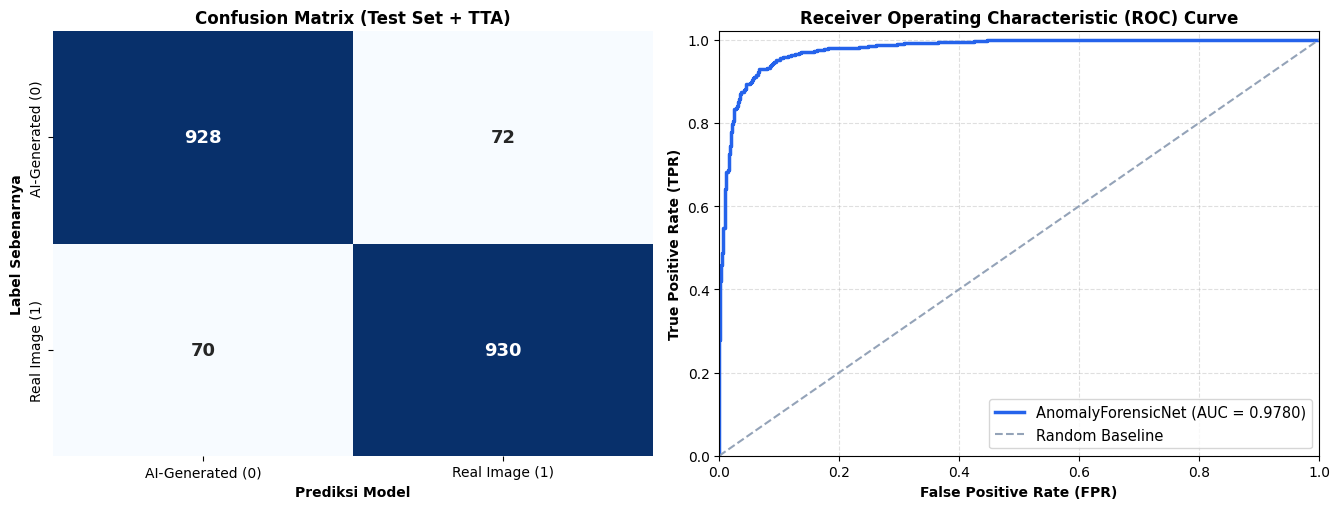

In [ ]:
# ==============================================================================
# 7. EVALUASI TEST SET (TTA), CONFUSION MATRIX & KURVA ROC (SEPERTI V4)
# ==============================================================================
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=device, weights_only=True))
model.eval()

test_preds, test_targets, test_probs_real = [], [], []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluasi Test Set (Horizontal Flip TTA)"):
        imgs = imgs.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            probs_orig = torch.softmax(model(imgs), dim=1)
            probs_flip = torch.softmax(model(torch.flip(imgs, dims=[3])), dim=1)
            probs = 0.5 * (probs_orig + probs_flip)

        test_probs_real.extend(probs[:, 1].cpu().numpy())
        test_preds.extend(probs.argmax(dim=1).cpu().numpy())
        test_targets.extend(labels.numpy())

test_acc = accuracy_score(test_targets, test_preds)
test_f1  = f1_score(test_targets, test_preds, average="macro")
test_auc = roc_auc_score(test_targets, test_probs_real)

print("=" * 68)
print(f"HASIL EVALUASI INDEPENDEN TEST SET (OWENSLAB/COMMUNITYFORENSICS)")
print("=" * 68)
print(f"Test Accuracy    : {test_acc * 100:.2f}%")
print(f"Test Macro F1    : {test_f1:.4f}")
print(f"Test ROC-AUC     : {test_auc:.4f}")
print("-" * 68)
print(classification_report(test_targets, test_preds, target_names=["AI-Generated (0)", "Real Image (1)"], digits=4))

# --- Plot Confusion Matrix & ROC Curve Berdampingan (Seperti V4) ---
cm = confusion_matrix(test_targets, test_preds)
fpr, tpr, _ = roc_curve(test_targets, test_probs_real)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["AI-Generated (0)", "Real Image (1)"],
    yticklabels=["AI-Generated (0)", "Real Image (1)"],
    annot_kws={"size": 13, "weight": "bold"}
)
axes[0].set_title("Confusion Matrix (Test Set + TTA)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Prediksi Model", fontweight="bold")
axes[0].set_ylabel("Label Sebenarnya", fontweight="bold")

axes[1].plot(fpr, tpr, color="#2563eb", lw=2.5, label=f"AnomalyForensicNet (AUC = {test_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="#94a3b8", lw=1.5, linestyle="--", label="Random Baseline")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.02])
axes[1].set_xlabel("False Positive Rate (FPR)", fontweight="bold")
axes[1].set_ylabel("True Positive Rate (TPR)", fontweight="bold")
axes[1].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(loc="lower right", fontsize=10.5)

plt.tight_layout()
plt.show()

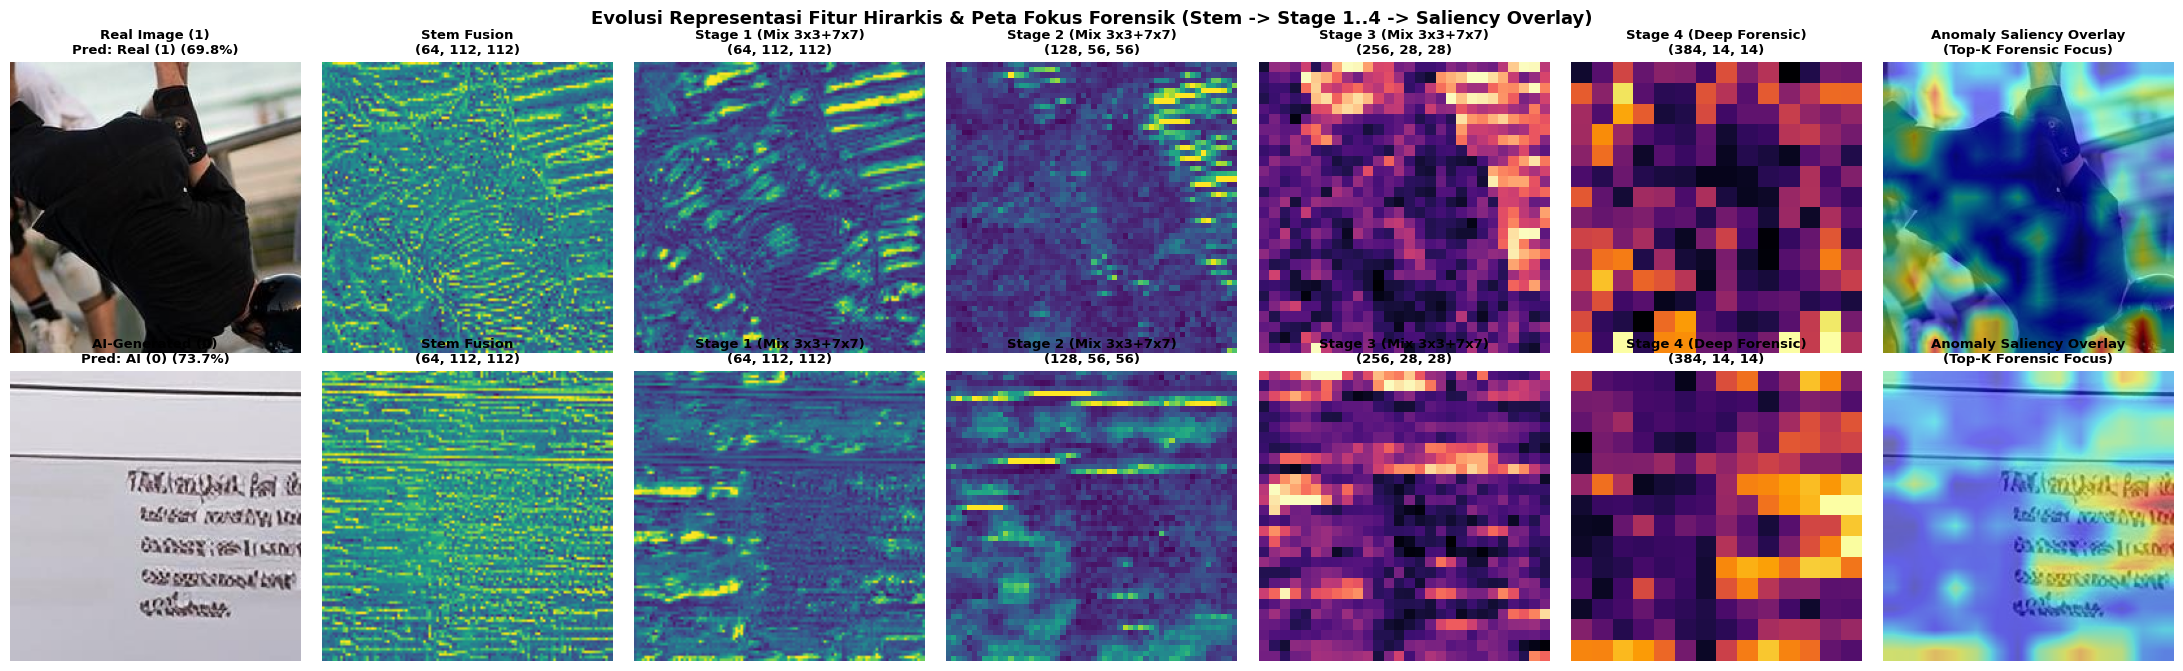

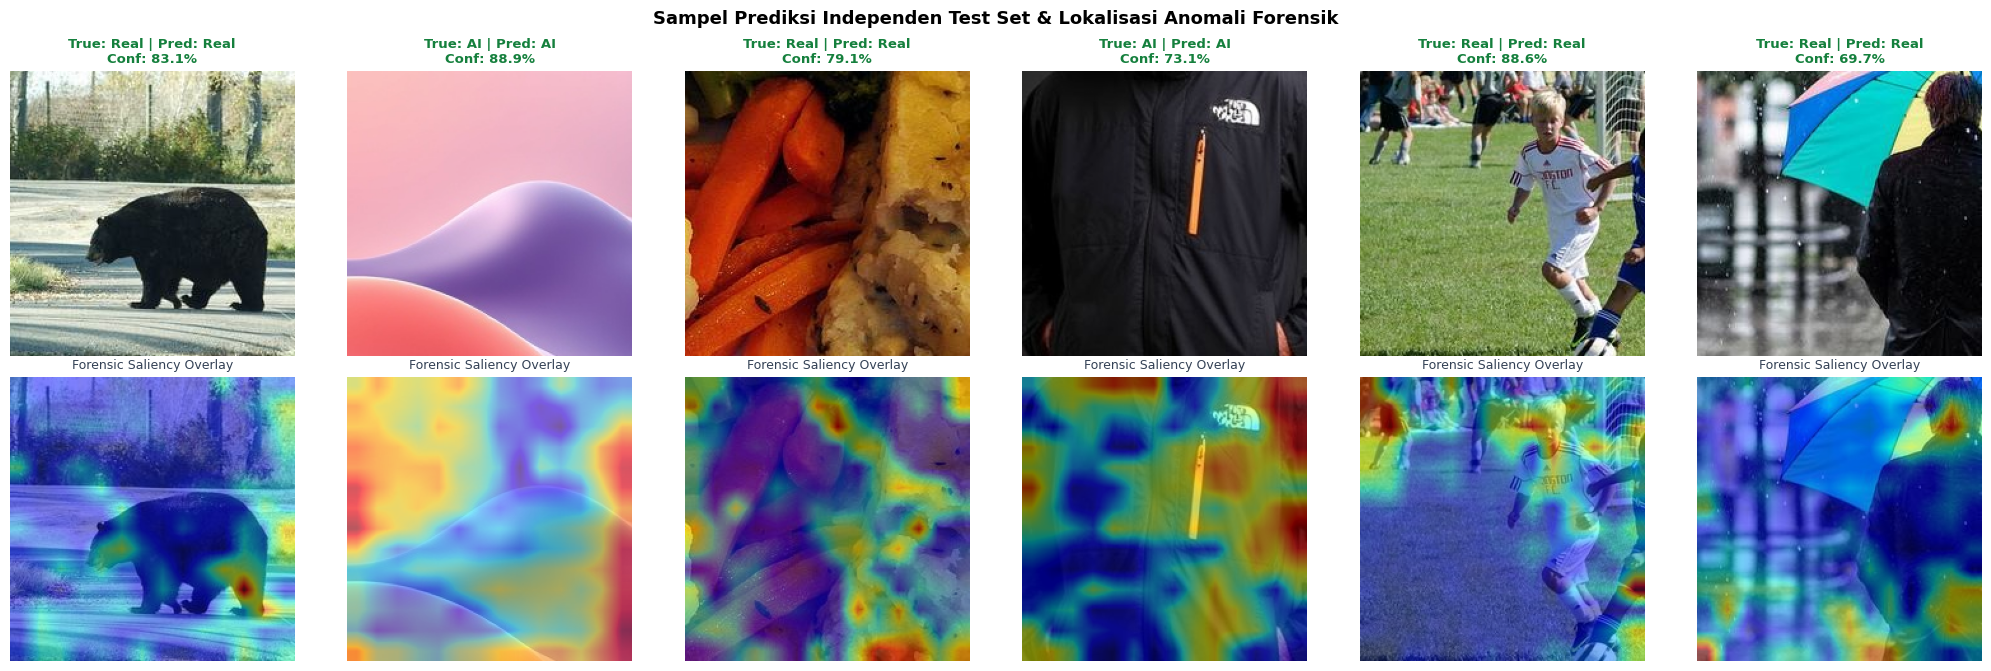

In [ ]:
# ==============================================================================
# 8. VISUALISASI AKTIVASI HIRARKIS ANTAR-STAGE & ANOMALY SALIENCY OVERLAY (V4 STYLE)
# ==============================================================================
def compute_anomaly_cam(s4_feat: torch.Tensor) -> np.ndarray:
    """Menghitung peta aktivasi anomali spasial dari Stage 4 (14x14 -> 224x224) untuk overlay visual."""
    cam = s4_feat.abs().mean(dim=0, keepdim=True).unsqueeze(0)
    cam_up = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)[0, 0]
    cam_np = cam_up.cpu().numpy()
    return (cam_np - cam_np.min()) / (cam_np.max() - cam_np.min() + 1e-6)

def visualize_hierarchical_stages(df: pd.DataFrame):
    """Menampilkan progresi feature map dari Input -> Stem -> Stage 1..4 -> Saliency Overlay seperti V4."""
    real_row = df[df["label"] == 1].iloc[1]
    ai_row = df[df["label"] == 0].iloc[1]
    samples = [("Real Image (1)", real_row), ("AI-Generated (0)", ai_row)]

    fig, axes = plt.subplots(2, 7, figsize=(22, 6.8))
    model.eval()

    with torch.no_grad():
        for r_idx, (lbl_name, row) in enumerate(samples):
            pil_img = Image.open(row["image_path"]).convert("RGB")
            x = eval_transform(pil_img).unsqueeze(0).to(device)
            s0, s1, s2, s3, s4 = model.forward_features(x)
            probs = torch.softmax(model(x), dim=1)[0]
            pred_cls = "Real (1)" if probs[1] >= 0.5 else "AI (0)"
            conf = max(probs[0].item(), probs[1].item()) * 100.0

            rgb_np = denorm_img(x[0])
            cam_np = compute_anomaly_cam(s4[0])

            stage_panels = [
                (rgb_np, f"{lbl_name}\nPred: {pred_cls} ({conf:.1f}%)", None),
                (norm_map(s0[0]), f"Stem Fusion\n{tuple(s0.shape[1:])}", "viridis"),
                (norm_map(s1[0]), f"Stage 1 (Mix 3x3+7x7)\n{tuple(s1.shape[1:])}", "viridis"),
                (norm_map(s2[0]), f"Stage 2 (Mix 3x3+7x7)\n{tuple(s2.shape[1:])}", "viridis"),
                (norm_map(s3[0]), f"Stage 3 (Mix 3x3+7x7)\n{tuple(s3.shape[1:])}", "magma"),
                (norm_map(s4[0]), f"Stage 4 (Deep Forensic)\n{tuple(s4.shape[1:])}", "inferno"),
            ]

            for c_idx, (arr, title, cmap) in enumerate(stage_panels):
                ax = axes[r_idx, c_idx]
                ax.imshow(arr if cmap is None else arr, cmap=cmap)
                ax.set_title(title, fontsize=9.5, fontweight="bold")
                ax.axis("off")

            ax_ov = axes[r_idx, 6]
            ax_ov.imshow(rgb_np)
            ax_ov.imshow(cam_np, cmap="jet", alpha=0.50)
            ax_ov.set_title("Anomaly Saliency Overlay\n(Top-K Forensic Focus)", fontsize=9.5, fontweight="bold")
            ax_ov.axis("off")

    plt.suptitle("Evolusi Representasi Fitur Hirarkis & Peta Fokus Forensik (Stem -> Stage 1..4 -> Saliency Overlay)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

visualize_hierarchical_stages(test_df)

# --- Grid Sampel Prediksi Test Set dengan Anomaly Saliency Overlay ---
def visualize_test_predictions(df: pd.DataFrame, n_samples: int = 6):
    sub = df.sample(n=min(n_samples, len(df)), random_state=SEED + 7).reset_index(drop=True)
    fig, axes = plt.subplots(2, n_samples, figsize=(3.4 * n_samples, 6.8))
    model.eval()

    with torch.no_grad():
        for i, (_, row) in enumerate(sub.iterrows()):
            pil_img = Image.open(row["image_path"]).convert("RGB")
            x = eval_transform(pil_img).unsqueeze(0).to(device)
            _, _, _, _, s4 = model.forward_features(x)
            probs = torch.softmax(model(x), dim=1)[0]
            pred_lbl = int(probs.argmax().item())
            true_lbl = int(row["label"])
            conf = probs[pred_lbl].item() * 100.0

            rgb_np = denorm_img(x[0])
            cam_np = compute_anomaly_cam(s4[0])
            ok = (pred_lbl == true_lbl)
            color = "#15803d" if ok else "#dc2626"
            names = {0: "AI", 1: "Real"}

            axes[0, i].imshow(rgb_np)
            axes[0, i].set_title(f"True: {names[true_lbl]} | Pred: {names[pred_lbl]}\nConf: {conf:.1f}%", fontsize=9.5, fontweight="bold", color=color)
            axes[0, i].axis("off")

            axes[1, i].imshow(rgb_np)
            axes[1, i].imshow(cam_np, cmap="jet", alpha=0.50)
            axes[1, i].set_title("Forensic Saliency Overlay", fontsize=9, color="#334155")
            axes[1, i].axis("off")

    plt.suptitle("Sampel Prediksi Independen Test Set & Lokalisasi Anomali Forensik", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

visualize_test_predictions(test_df, n_samples=6)

In [ ]:
# ==============================================================================
# 9. VERIFIKASI CHECKPOINT & AUTO-DOWNLOAD UNTUK STREAMLIT (app.py)
# ==============================================================================
if os.path.exists(MODEL_SAVE_PATH):
    size_mb = os.path.getsize(MODEL_SAVE_PATH) / (1024 * 1024)
    print(f"Checkpoint siap digunakan di app.py: {MODEL_SAVE_PATH} ({size_mb:.2f} MB)")
    try:
        from google.colab import files
        files.download(MODEL_SAVE_PATH)
    except Exception:
        print("Berjalan di lingkungan lokal — file tersimpan langsung di direktori kerja.")

Checkpoint siap digunakan di app.py: best_anomaly_forensicnet_cf.pth (9.13 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>